In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import datetime
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df = pd.read_csv("/content/AusApparalSales4thQrt2020.csv", parse_dates=["Date"])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    7560 non-null   datetime64[ns]
 1   Time    7560 non-null   object        
 2   State   7560 non-null   object        
 3   Group   7560 non-null   object        
 4   Unit    7560 non-null   int64         
 5   Sales   7560 non-null   int64         
dtypes: datetime64[ns](1), int64(2), object(3)
memory usage: 354.5+ KB


In [ ]:
df.isna().sum()

,0
Date,0
Time,0
State,0
Group,0
Unit,0
Sales,0


In [ ]:
df.notna().sum()

,0
Date,7560
Time,7560
State,7560
Group,7560
Unit,7560
Sales,7560


In [ ]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df_dataonly = df.select_dtypes(include=[np.number])

In [ ]:
df_dataonly.head()

,Unit,Sales
0,8,20000
1,8,20000
2,4,10000
3,15,37500
4,3,7500


In [ ]:
normalizer = MinMaxScaler()

In [ ]:
normalized_data = normalizer.fit_transform(df_dataonly)

In [ ]:
df.head(2)

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000


In [ ]:
df.groupby(by="Date", axis="index")[["Unit", "Sales"]].sum()

/tmp/ipykernel_1874/461937341.py:1: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  df.groupby(by="Date", axis="index")[["Unit", "Sales"]].sum()


,Unit,Sales
Date,,
2020-10-01,1488,3720000
2020-10-02,1486,3715000
2020-10-03,1556,3890000
2020-10-04,1488,3720000
2020-10-05,1545,3862500
...,...,...
2020-12-26,1886,4715000
2020-12-27,1855,4637500
2020-12-28,1838,4595000


In [ ]:
df_unit_and_sales = df.groupby(by="Date",axis='index').agg({'Unit':'sum','Sales':'sum'})

/tmp/ipykernel_1874/2566941901.py:1: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  df_unit_and_sales = df.groupby(by="Date",axis='index').agg({'Unit':'sum','Sales':'sum'})


In [ ]:
df_unit_and_sales.head()

,Unit,Sales
Date,,
2020-10-01,1488,3720000
2020-10-02,1486,3715000
2020-10-03,1556,3890000
2020-10-04,1488,3720000
2020-10-05,1545,3862500


In [ ]:
df_unit_and_sales.index.unique()

DatetimeIndex(['2020-10-01', '2020-10-02', '2020-10-03', '2020-10-04',
               '2020-10-05', '2020-10-06', '2020-10-07', '2020-10-08',
               '2020-10-09', '2020-10-10', '2020-10-11', '2020-10-12',
               '2020-10-13', '2020-10-14', '2020-10-15', '2020-10-16',
               '2020-10-17', '2020-10-18', '2020-10-19', '2020-10-20',
               '2020-10-21', '2020-10-22', '2020-10-23', '2020-10-24',
               '2020-10-25', '2020-10-26', '2020-10-27', '2020-10-28',
               '2020-10-29', '2020-10-30', '2020-11-01', '2020-11-02',
               '2020-11-03', '2020-11-04', '2020-11-05', '2020-11-06',
               '2020-11-07', '2020-11-08', '2020-11-09', '2020-11-10',
               '2020-11-11', '2020-11-12', '2020-11-13', '2020-11-14',
               '2020-11-15', '2020-11-16', '2020-11-17', '2020-11-18',
               '2020-11-19', '2020-11-20', '2020-11-21', '2020-11-22',
               '2020-11-23', '2020-11-24', '2020-11-25', '2020-11-26',
      

In [ ]:
df["Date"].min()

Timestamp('2020-10-01 00:00:00')

In [ ]:
df["Date"].max()

Timestamp('2020-12-30 00:00:00')

In [ ]:
df_oct = df_unit_and_sales.loc['2020-10-01':'2020-10-31']

In [ ]:
df_nov = df_unit_and_sales.loc['2020-11-01':'2020-11-30']

In [ ]:
df_dec = df_unit_and_sales.loc['2020-12-01':'2020-12-31']

In [ ]:
df_dec.head()

,Unit,Sales
Date,,
2020-12-01,1786,4465000
2020-12-02,1826,4565000
2020-12-03,1783,4457500
2020-12-04,1793,4482500
2020-12-05,1823,4557500


<Axes: xlabel='Date', ylabel='Sales'>

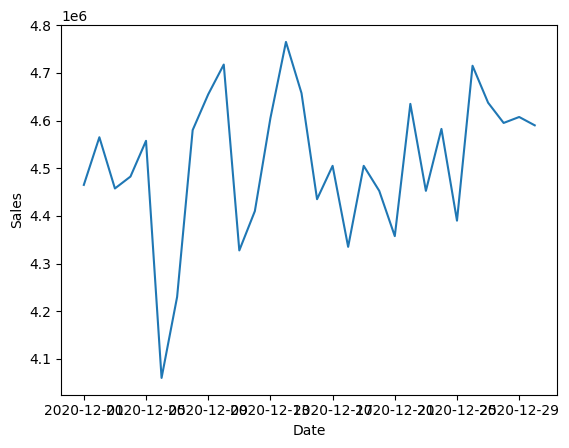

In [ ]:
sns.lineplot(data=df_dec, x=df_dec.index, y="Sales")

(array([18597., 18601., 18605., 18609., 18613., 18617., 18621., 18625.]),
 [Text(18597.0, 0, '2020-12-01'),
  Text(18601.0, 0, '2020-12-05'),
  Text(18605.0, 0, '2020-12-09'),
  Text(18609.0, 0, '2020-12-13'),
  Text(18613.0, 0, '2020-12-17'),
  Text(18617.0, 0, '2020-12-21'),
  Text(18621.0, 0, '2020-12-25'),
  Text(18625.0, 0, '2020-12-29')])

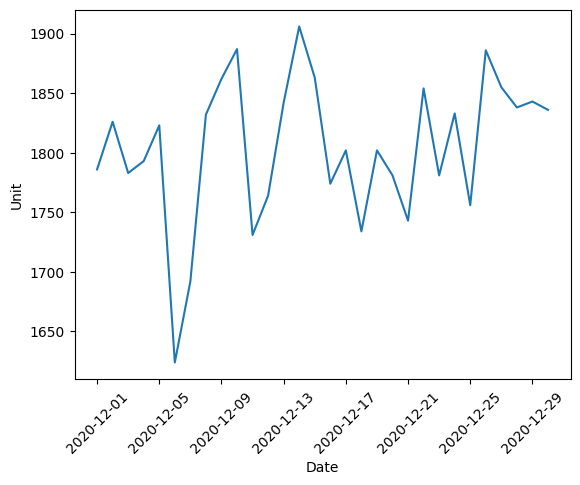

In [ ]:
sns.lineplot(data=df_dec, x=df_dec.index, y="Unit")
plt.xticks(rotation=45)

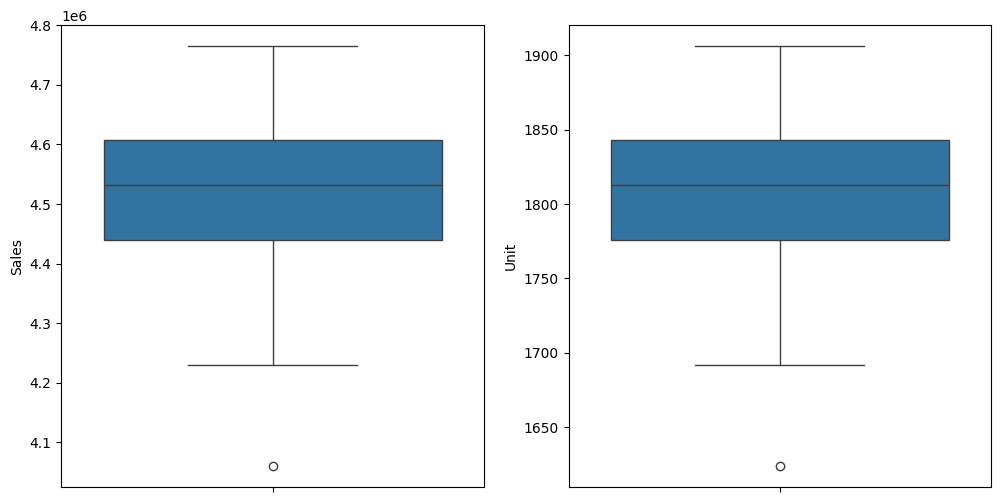

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
sns.boxplot(data=df_dec, y="Sales",ax=ax[0])
sns.boxplot(data=df_dec, y="Unit",ax=ax[1])
plt.show()

[Text(0.5, 1.0, 'December Sales')]

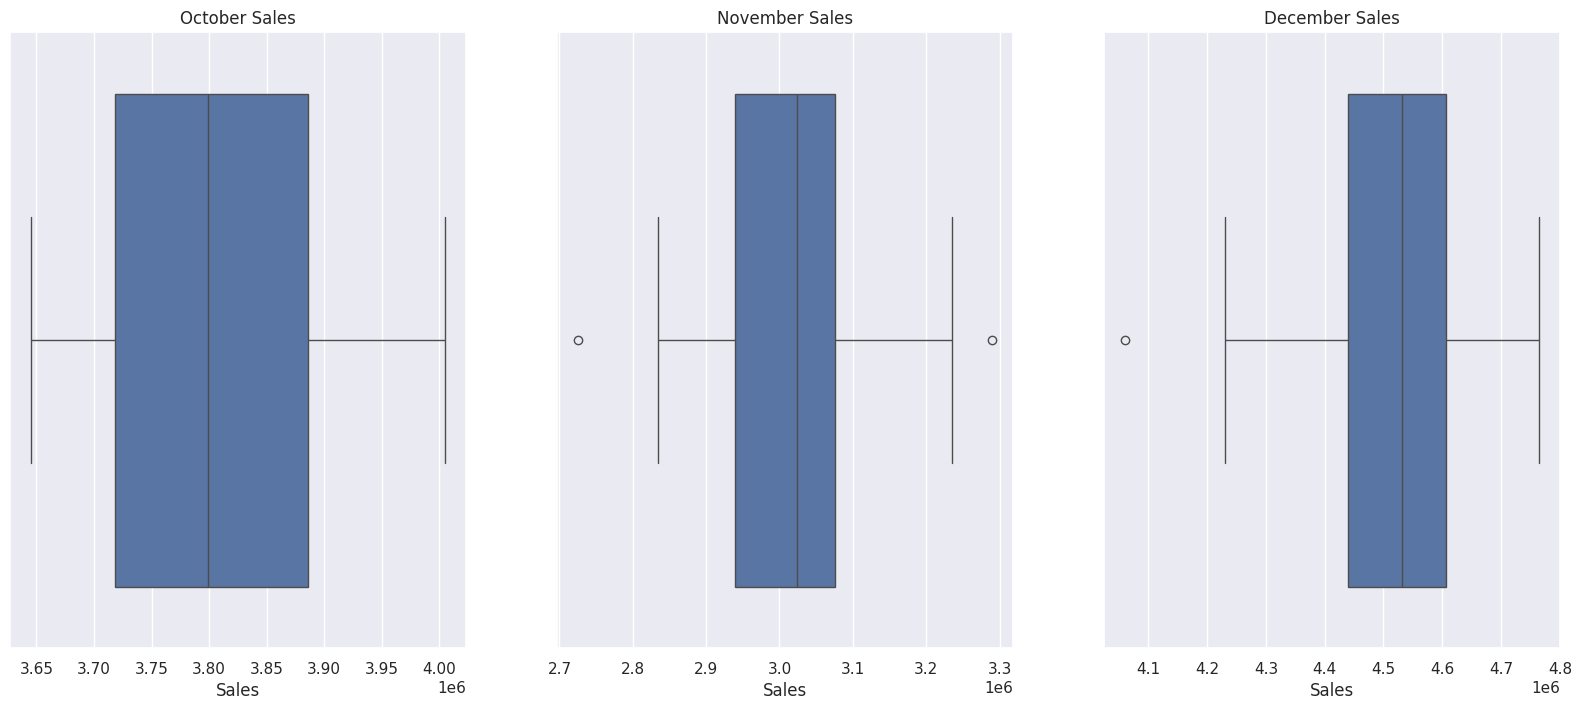

In [ ]:

sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
bp_oct = sns.boxplot(x='Sales', data=df_oct, ax=axes[0])
bp_nov = sns.boxplot(x='Sales', data=df_nov, ax=axes[1])
bp_dec = sns.boxplot(x='Sales', data=df_dec, ax=axes[2])
bp_oct.set(title='October Sales')
bp_nov.set(title='November Sales')
bp_dec.set(title='December Sales')

In [ ]:
df_dec.describe()

,Unit,Sales
count,30.000000,3.000000e+01
mean,1804.400000,4.511000e+06
std,61.370329,1.534258e+05
min,1624.000000,4.060000e+06
25%,1775.750000,4.439375e+06
50%,1812.500000,4.531250e+06
75%,1842.750000,4.606875e+06
max,1906.000000,4.765000e+06


In [ ]:
df_nov["Month"] = "November"
df_dec["Month"] = "December"
df_oct["Month"] = "October"

/tmp/ipykernel_1874/3440487945.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nov["Month"] = "November"
/tmp/ipykernel_1874/3440487945.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dec["Month"] = "December"
/tmp/ipykernel_1874/3440487945.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing

In [ ]:
df_nov.head()

,Unit,Sales,Month
Date,,,
2020-11-01,1208,3020000,November
2020-11-02,1090,2725000,November
2020-11-03,1151,2877500,November
2020-11-04,1257,3142500,November
2020-11-05,1230,3075000,November


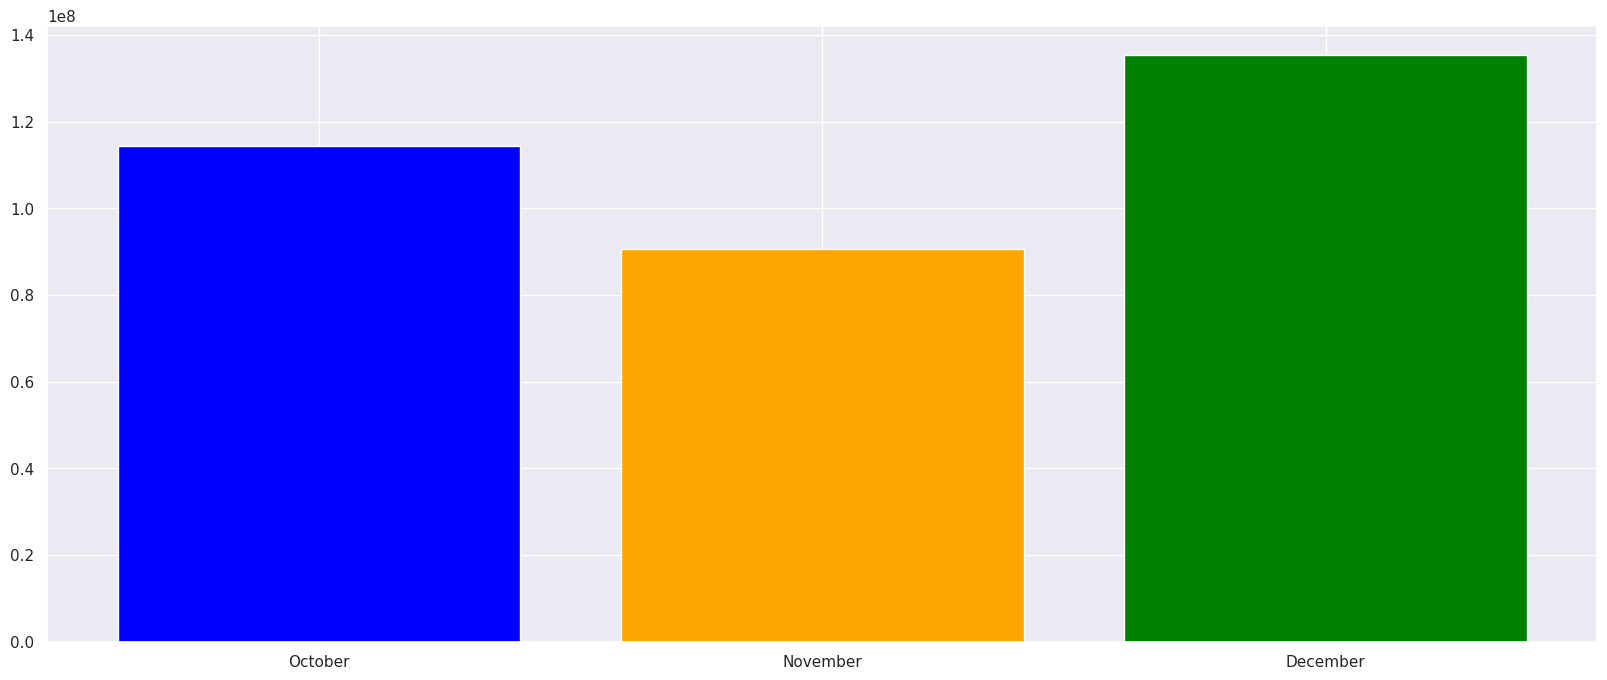

In [ ]:
plt.bar(['October', 'November', "December"], [df_oct["Sales"].sum(), df_nov["Sales"].sum(), df_dec["Sales"].sum()], color=['blue', 'orange', 'green'])
plt.show()

<Axes: xlabel='Date', ylabel='Sales'>

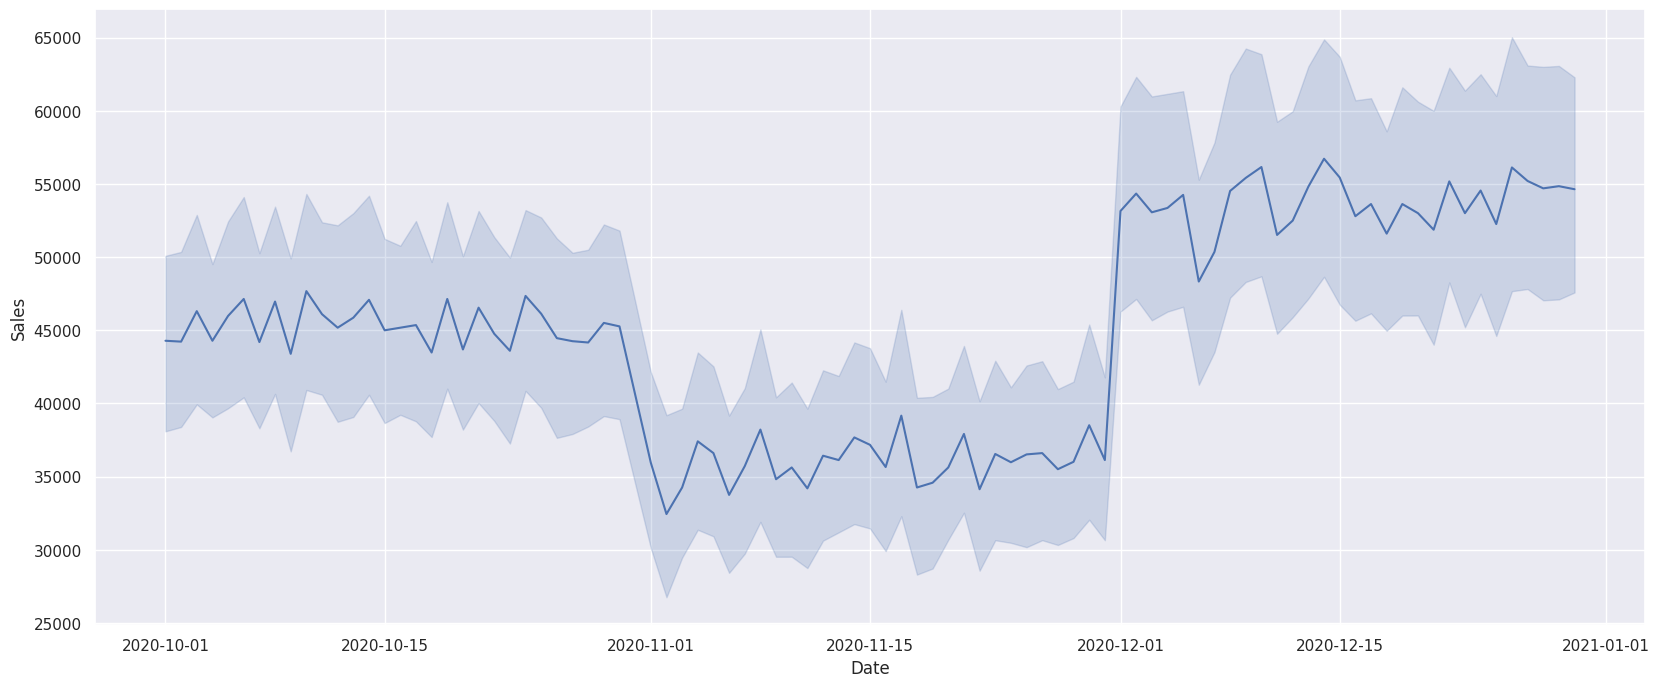

In [ ]:
sns.set(rc={'figure.figsize':(20,8)})
sns.lineplot(x = 'Date', y = 'Sales', data = df)

In [ ]:
oct_days = df_oct.index.day
oct_days = oct_days.astype(str)
nov_days = df_nov.index.day
nov_days = nov_days.astype(str)
dec_days = df_dec.index.day
dec_days = dec_days.astype(str)

In [ ]:
oct_days

Index(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13',
       '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25',
       '26', '27', '28', '29', '30'],
      dtype='object', name='Date')

/tmp/ipykernel_1874/2724183847.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  o = bp_oct.set_xticklabels(oct_days)
/tmp/ipykernel_1874/2724183847.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  n = bp_nov.set_xticklabels(nov_days)
/tmp/ipykernel_1874/2724183847.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  d = bp_dec.set_xticklabels(dec_days)


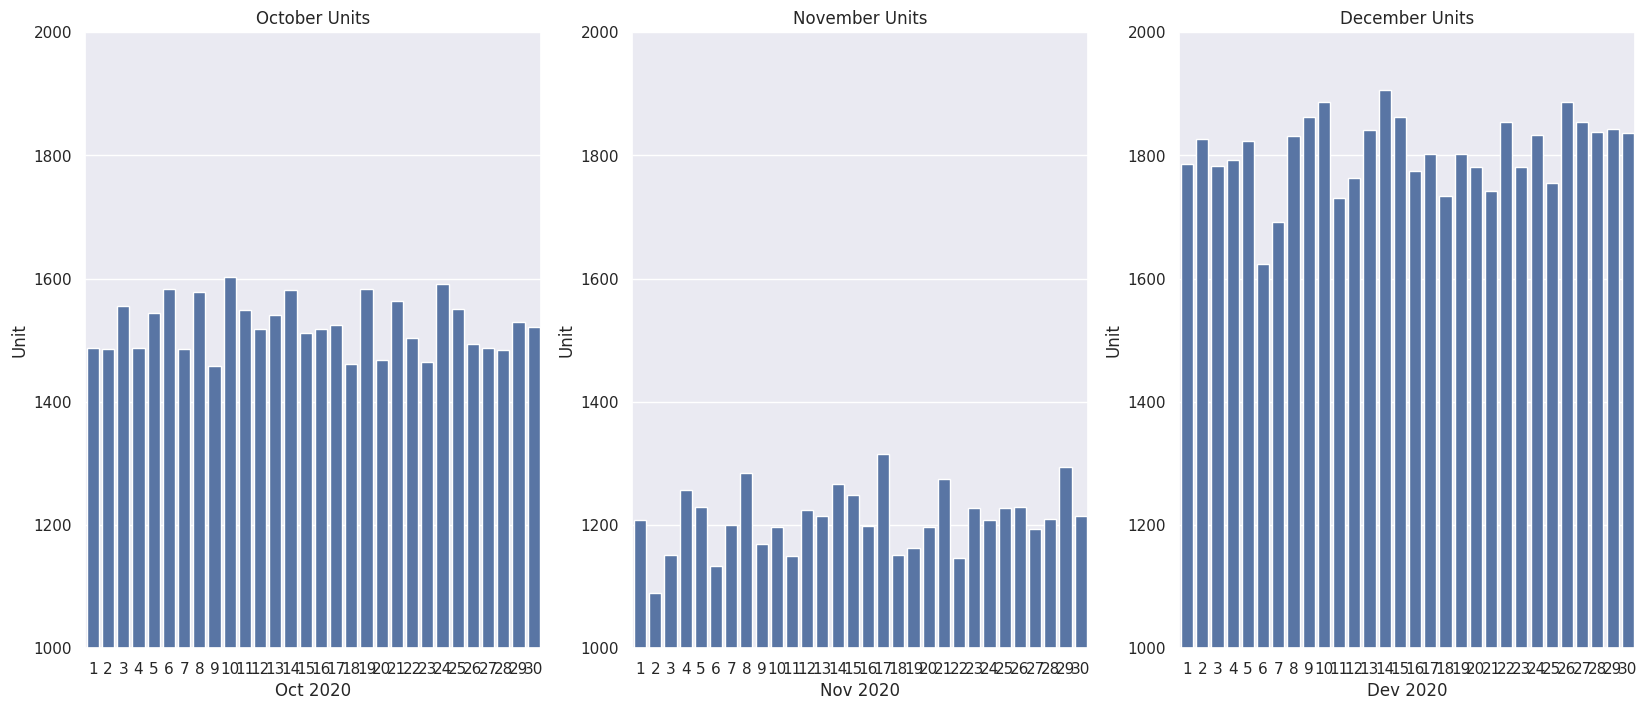

In [ ]:
sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
bp_oct = sns.barplot(x = df_oct.index, y='Unit', data=df_oct, ax=axes[0])
bp_nov = sns.barplot(x = df_nov.index, y='Unit', data=df_nov, ax=axes[1])
bp_dec = sns.barplot(x = df_dec.index, y='Unit', data=df_dec, ax=axes[2])
bp_oct.set(xlabel='Oct 2020', title='October Units')
bp_nov.set(xlabel='Nov 2020', title='November Units')
bp_dec.set(xlabel='Dev 2020', title='December Units')
bp_oct.set(ylim=(1000, 2000))
bp_nov.set(ylim=(1000, 2000))
bp_dec.set(ylim=(1000, 2000))
o = bp_oct.set_xticklabels(oct_days)
n = bp_nov.set_xticklabels(nov_days)
d = bp_dec.set_xticklabels(dec_days)

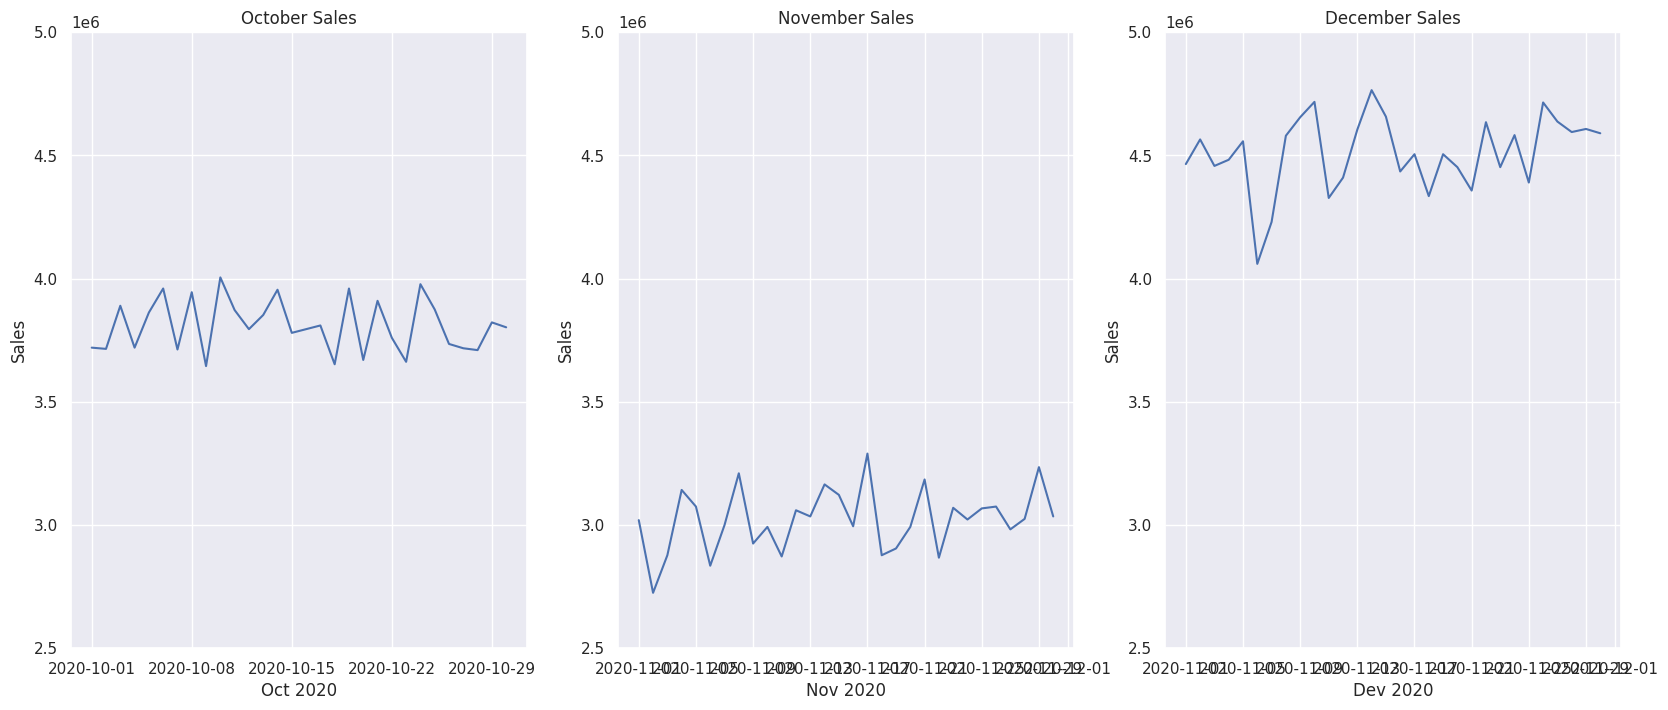

In [ ]:
import matplotlib

sns.set(rc={'figure.figsize':(20,8)})
fig, axes = plt.subplots(1, 3)
lp_oct = sns.lineplot(x = df_oct.index, y = 'Sales', data=df_oct, ax=axes[0])
lp_nov = sns.lineplot(x = df_nov.index, y = 'Sales', data=df_nov, ax = axes[1])
lp_dec = sns.lineplot(x = df_nov.index, y = 'Sales', data=df_dec, ax = axes[2])
lp_oct.set(ylim=(2.5e6, 5.0e6))
lp_nov.set(ylim=(2.5e6, 5.0e6))
lp_dec.set(ylim=(2.5e6, 5.0e6))
lp_oct.set(xlabel='Oct 2020', title='October Sales')
lp_nov.set(xlabel='Nov 2020', title='November Sales')
lp_dec.set(xlabel='Dev 2020', title='December Sales')

loc = matplotlib.dates.DayLocator(bymonthday=range(1, 30, 7))

lp_oct.xaxis.set_major_locator(loc)

In [ ]:
df.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


In [ ]:
df.groupby(["State", "Group"])[["Sales"]].sum().reset_index()

,State,Group,Sales
0,NSW,Kids,18587500
1,NSW,Men,19022500
2,NSW,Seniors,18187500
3,NSW,Women,19172500
4,NT,Kids,5700000
5,NT,Men,5762500
6,NT,Seniors,5465000
7,NT,Women,5652500
8,QLD,Kids,8510000
9,QLD,Men,8392500


In [ ]:
pd.pivot_table(df, values="Sales", index=["State"], columns=["Group"], aggfunc=np.sum, fill_value=0).reset_index()

/tmp/ipykernel_1874/1990090004.py:1: FutureWarning: The provided callable <function sum at 0x7c668b75ab60> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pd.pivot_table(df, values="Sales", index=["State"], columns=["Group"], aggfunc=np.sum, fill_value=0).reset_index()


Group,State,Kids,Men,Seniors,Women
0,NSW,18587500,19022500,18187500,19172500
1,NT,5700000,5762500,5465000,5652500
2,QLD,8510000,8392500,8190000,8325000
3,SA,14515000,14655000,14717500,14970000
4,TAS,5775000,5757500,5650000,5577500
5,VIC,26360000,26407500,26315000,26482500
6,WA,5625000,5752500,5512500,5262500


In [ ]:
group_pivot = pd.pivot_table(df[['Group','Sales','Unit']], index='Group', aggfunc=['sum', 'mean'])
group_pivot

sum                 mean           
            Sales   Unit         Sales       Unit
Group                                            
Kids     85072500  34029  45011.904762  18.004762
Men      85750000  34300  45370.370370  18.148148
Seniors  84037500  33615  44464.285714  17.785714
Women    85442500  34177  45207.671958  18.083069

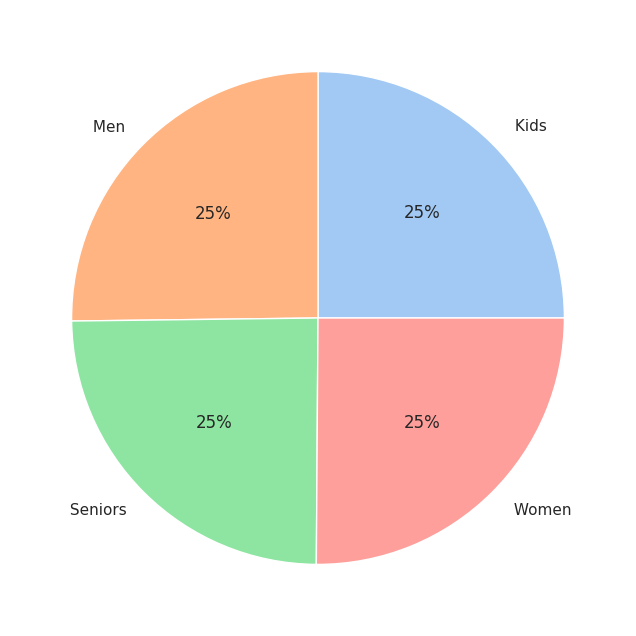

In [ ]:
labels = group_pivot['mean']['Sales'].index.to_list()

colors = sns.color_palette('pastel')[0:5]
plt.pie(group_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()

In [ ]:
df.head()

,Date,Time,State,Group,Unit,Sales
0,2020-10-01,Morning,WA,Kids,8,20000
1,2020-10-01,Morning,WA,Men,8,20000
2,2020-10-01,Morning,WA,Women,4,10000
3,2020-10-01,Morning,WA,Seniors,15,37500
4,2020-10-01,Afternoon,WA,Kids,3,7500


In [ ]:
time_pivot = pd.pivot_table(df[['Time','Sales','Unit']], index='Time', aggfunc=['sum', 'mean'])
time_pivot

sum                 mean           
               Sales   Unit         Sales       Unit
Time                                                
Afternoon  114007500  45603  45241.071429  18.096429
Evening    112087500  44835  44479.166667  17.791667
Morning    114207500  45683  45320.436508  18.128175

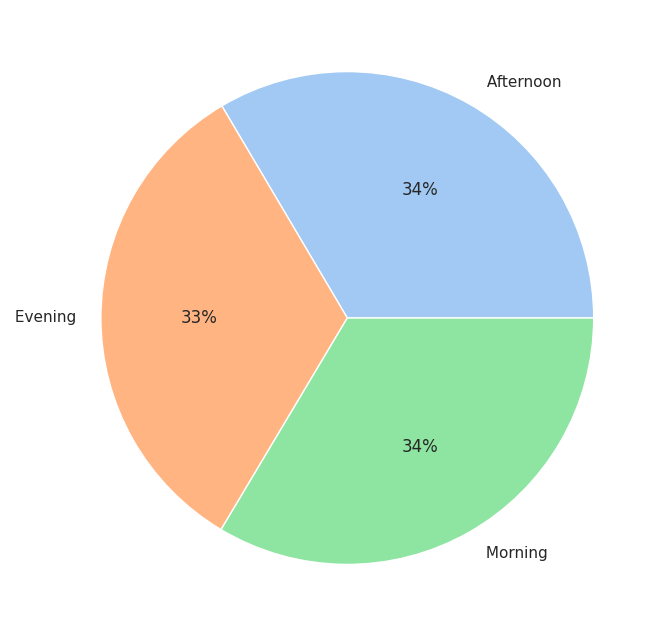

In [ ]:
labels = time_pivot['mean']['Sales'].index.to_list()

colors = sns.color_palette('pastel')[0:5]
plt.pie(time_pivot['mean']['Sales'], labels=labels, colors=colors, autopct='%.0f%%')
plt.show()